# Assignment: sentiment on a different dataset

Use the 2,000-document Pang–Lee movie review polarity corpus distributed
by NLTK. The complete corpus is supplied as
[movie_reviews.csv.gz](../data/movie_reviews.csv.gz), with the
[original README](../data/movie-reviews-README.txt). See the
[authors' data page](https://www.cs.cornell.edu/people/pabo/movie-review-data/).
Labels were derived from review ratings, not independently annotated
sentence emotions. This differs from short, paired hotel comments.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from IPython.display import display
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

nltk.data.path.insert(0, str(Path('../data/nltk_data').resolve()))
reviews = pd.read_csv('../data/movie_reviews.csv.gz')
assert reviews.shape == (2000, 3)
assert reviews.file_id.is_unique and reviews[['review', 'label']].notna().all().all()
reviews['normalized'] = reviews.review.map(lambda text: ' '.join(text.split()))
print('Duplicate normalized texts:', int(reviews.normalized.duplicated().sum()))
assert reviews.groupby('normalized').label.nunique().max() == 1
reviews = reviews.drop_duplicates('normalized').copy()
display(reviews.groupby('label').agg(documents=('file_id', 'size')))
print('Review length (words):')
display(reviews.normalized.str.split().str.len().describe())

Duplicate normalized texts: 0


,documents
label,
neg,1000
pos,1000


Review length (words):


count    2000.00000
mean      746.34050
std       328.42529
min        17.00000
25%       526.75000
50%       696.50000
75%       904.00000
max      2678.00000
Name: normalized, dtype: float64

## Processing choices and fixed evaluation split

Retain punctuation and negation for VADER. Remove only repeated whitespace
for duplicate detection, before splitting. A stratified 75/25 split with
seed 42 supplies the same unseen test reviews to every method. The TF-IDF
vocabulary is learned only when fitting the training pipeline.

In [2]:
train, test = train_test_split(reviews, test_size=0.25, stratify=reviews.label, random_state=42)
assert set(train.file_id).isdisjoint(test.file_id)
assert set(train.normalized).isdisjoint(test.normalized)
print('Train/test documents:', len(train), len(test))
analyzer = SentimentIntensityAnalyzer()
reviews['vader_score'] = reviews.review.map(lambda text: analyzer.polarity_scores(text)['compound'])
reviews['vader_label'] = np.select(
    [reviews.vader_score.le(-0.05), reviews.vader_score.ge(0.05)],
    ['neg', 'pos'], default='neutral',
)
test = reviews.loc[test.index].copy()
covered = test.vader_label.ne('neutral')
print('VADER test coverage with standard neutral band:', round(covered.mean(), 4))
print('Three-way output scored against binary labels:', round(accuracy_score(test.label, test.vader_label), 4))
print('Accuracy among non-neutral predictions:', round(accuracy_score(test.loc[covered, 'label'], test.loc[covered, 'vader_label']), 4))
vader_binary = np.where(test.vader_score.ge(0), 'pos', 'neg')

Train/test documents: 1500 500


VADER test coverage with standard neutral band: 1.0
Three-way output scored against binary labels: 0.65
Accuracy among non-neutral predictions: 0.65


In [3]:
baseline = DummyClassifier(strategy='most_frequent').fit(train.review, train.label)
model = make_pipeline(
    TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=20000, sublinear_tf=True),
    LogisticRegression(max_iter=1000, random_state=42),
)
model.fit(train.review, train.label)
supervised = model.predict(test.review)
predictions = {'Majority baseline': baseline.predict(test.review),
               'VADER (binary threshold 0)': vader_binary, 'TF-IDF + logistic regression': supervised}
metrics = pd.DataFrame([
    {'method': name, 'accuracy': accuracy_score(test.label, prediction),
     'balanced_accuracy': balanced_accuracy_score(test.label, prediction)}
    for name, prediction in predictions.items()
])
display(metrics)
print(classification_report(test.label, supervised, digits=3))
assert len(test) == 500 and len(supervised) == 500
assert set(supervised) <= {'neg', 'pos'}
assert metrics.set_index('method').loc['TF-IDF + logistic regression', 'accuracy'] > 0.5
metrics.to_csv('movie-review-metrics.csv', index=False)

,method,accuracy,balanced_accuracy
0,Majority baseline,0.500,0.500
1,VADER (binary threshold 0),0.650,0.650
2,TF-IDF + logistic regression,0.856,0.856


              precision    recall  f1-score   support

         neg      0.862     0.848     0.855       250
         pos      0.850     0.864     0.857       250

    accuracy                          0.856       500
   macro avg      0.856     0.856     0.856       500
weighted avg      0.856     0.856     0.856       500



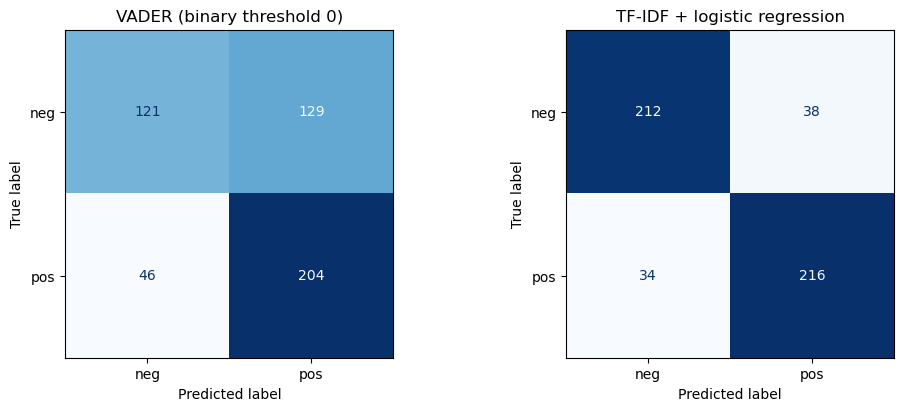

VADER error summary (file IDs, no invented annotations):


,file_id,label,vader_score,vader_binary
654,neg/cv654_19345.txt,neg,0.9737,pos
839,neg/cv839_22807.txt,neg,0.4170,pos
1385,pos/cv385_29741.txt,pos,-0.6689,neg
1905,pos/cv905_29114.txt,pos,-0.9159,neg
391,neg/cv391_11615.txt,neg,0.9986,pos
435,neg/cv435_24355.txt,neg,0.8807,pos
35,neg/cv035_3343.txt,neg,0.9847,pos
573,neg/cv573_29384.txt,neg,0.9169,pos
156,neg/cv156_11119.txt,neg,0.9952,pos
700,neg/cv700_23163.txt,neg,0.9898,pos


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')
for axis, name in zip(axes, ['VADER (binary threshold 0)', 'TF-IDF + logistic regression']):
    ConfusionMatrixDisplay.from_predictions(test.label, predictions[name], labels=['neg', 'pos'],
                                           ax=axis, colorbar=False, cmap='Blues')
    axis.set_title(name)
fig.savefig('movie-review-confusion.png', dpi=160)
plt.show()
test['vader_binary'] = vader_binary
test['supervised_label'] = supervised
print('VADER error summary (file IDs, no invented annotations):')
display(test.loc[test.label.ne(test.vader_binary), ['file_id', 'label', 'vader_score', 'vader_binary']].head(10))
test[['file_id', 'label', 'vader_score', 'vader_binary', 'supervised_label']].to_csv('movie-review-predictions.csv', index=False)

## What changed in the new domain?

VADER uses a fixed lexicon; it is not trained on these movie reviews. Long
texts can contain strongly positive descriptions of a disliked film, and
compound scores can saturate. A domain-trained TF-IDF model can associate
repeated expressions with rating-derived labels, while its bigrams retain
some local context. The measured table compares both with a 50% baseline
using the same held-out documents.

The balanced corpus is artificial, reviews are already lowercased, and
reviewer/film identifiers are unavailable. Related reviews could cross a
random document split. Thus, this is a reproducible document-level exercise,
not an estimate of performance on new films, new reviewers, hotel guests,
or the current internet. Neutral VADER outputs are reported explicitly;
converting them to binary predictions uses the stated threshold rather
than silently discarding difficult examples. No threshold was tuned using
the test set.